# Tema 13 · Datos en el tiempo: series temporales y ventanas

Predecir el futuro a partir del pasado sin mirar el futuro por accidente.

Este cuaderno es el tema 13 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/13-datos-en-el-tiempo-series-temporales-y-ventanas/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

¿Qué temperatura va a hacer mañana en La Paz? Tienes diez años de registros, día por día. Parece un problema de regresión como los de los temas 6 y 11: una tabla con columnas, un objetivo y un modelo. Pero hay una diferencia de fondo. En el Titanic, el orden de los pasajeros no importaba: podías barajarlos sin perder nada. En una serie de tiempo, **el orden es la información**: lo que pasó ayer ayuda a predecir hoy, y lo que pasa mañana todavía no se sabe.

Eso trae dos trabajos nuevos. Primero, hay que **convertir la serie en una tabla**, con columnas que resuman el pasado reciente. Segundo, hay que **evaluar sin mirar el futuro**: si el modelo estudia con datos posteriores a los que debe predecir, el puntaje miente. Es la fuga de datos del tema 10, en una versión todavía más fácil de cometer.

En este tema vas a:

- cargar y graficar una serie con **índice de fechas** en pandas, y remuestrearla;
- reconocer **tendencia**, **estacionalidad** y **ruido**, y medir la **autocorrelación**;
- crear variables de **ventana deslizante**: rezagos, media y desviación móviles;
- dividir respetando el tiempo con **`TimeSeriesSplit`** y explicar por qué no se baraja;
- rellenar faltantes con **forward-fill** sin usar el futuro;
- comparar un modelo con una **línea base ingenua**: «mañana igual que hoy».

Necesitas pandas (tema 4), la validación cruzada (tema 7), la fuga de datos (tema 10) y `HistGradientBoosting` (tema 11; aquí usamos su versión para predecir números, `HistGradientBoostingRegressor`).

## Actividad: la ventana

En la actividad tienes 60 días reales de temperatura media en La Paz, del 21 de mayo al 19 de julio de 2024. El rectángulo es la **ventana**: los días que el modelo puede mirar. Su borde derecho es «hoy». El anillo, con una línea punteada hacia abajo, marca el **objetivo**: el día que queremos predecir. Debajo aparece en vivo la fila de la tabla que sale de esa ventana.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/13-datos-en-el-tiempo-series-temporales-y-ventanas/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Arrastra la ventana (o usa el deslizador «Hoy») y mira cómo cambia la fila. Cada posición de la ventana es **una fila** de la tabla: con 60 días salen decenas de filas.
2. Agranda la ventana. ¿Cambian «ayer» y «anteayer»? ¿Y la media y la desviación?
3. Sube el horizonte a 7 días. Ahora el objetivo queda lejos de la ventana: ¿te parece más fácil o más difícil adivinarlo?
4. Con «Dividir por tiempo», las primeras filas entrenan y las últimas validan. Cuenta las respuestas de validación que ya se vieron al entrenar.
5. Pulsa «Barajar». Busca un punto coral y lleva la ventana hasta que su objetivo sea ese punto. ¿Dónde aparece esa misma temperatura entre las filas de entrenamiento?

Lo que viste en el paso 5 es la **fuga temporal**: al barajar, la fila del día siguiente suele quedar en el entrenamiento, y su «ayer» es justo la respuesta que debía adivinar la validación. El modelo rinde el examen con la hoja de respuestas a la vista.

## Diez años de temperatura en La Paz

Vamos a usar datos reales del **archivo histórico de Open-Meteo**, un servicio gratuito que no pide registrarse ni usar una clave. Le pedimos la temperatura media diaria de La Paz entre el 1 de enero de 2015 y el 31 de diciembre de 2024. El rango es fijo y ya pasó, así que cada vez que corras el código vas a obtener los mismos números. Necesitas conexión a internet: la descarga pesa unos 60 KB.

Dos detalles sobre estos datos. No son las lecturas de un termómetro en una calle de la ciudad: son un **reanálisis** llamado ERA5-Land, una estimación que combina observaciones (de estaciones, satélites, aviones y boyas) con un modelo del clima, en una cuadrícula de unos 11 km de lado. Por eso no tienen huecos, y por eso no tienen por qué coincidir con lo que marca un termómetro concreto, sobre todo en un terreno con tanto desnivel como el de La Paz: cada valor representa toda una celda de la cuadrícula. Para aprender a predecir, son perfectos.

**Fuente de los datos.** [Weather data by Open-Meteo.com](https://open-meteo.com/), con licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/deed.es). Open-Meteo los calcula con el reanálisis ERA5-Land (Muñoz Sabater, 2019, ECMWF, [doi:10.24381/cds.e2161bac](https://doi.org/10.24381/cds.e2161bac)). Los gráficos y las tablas de este tema son cálculos nuestros a partir de esos datos.

Una **API** (interfaz de programación, en inglés *application programming interface*) es aquí una dirección web que, en lugar de una página, devuelve datos. Los parámetros van escritos en la misma dirección, después de un `?`, y `urlencode` los escribe en el formato correcto. Le pedimos a la API un archivo CSV. Las tres primeras líneas describen el lugar (coordenadas, altura y zona horaria) y la tabla empieza en la cuarta: por eso `skiprows=3`. Con `index_col=0` y `parse_dates=True`, la columna de fechas se vuelve el **índice**, de tipo fecha. Eso es lo que hace a una tabla una **serie de tiempo** para pandas.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from urllib.parse import urlencode

# Archivo histórico de Open-Meteo: gratis, sin clave, licencia CC BY 4.0
API = "https://archive-api.open-meteo.com/v1/archive"
parametros = {
    "latitude": -16.50,             # La Paz
    "longitude": -68.15,
    "start_date": "2015-01-01",     # un rango fijo y ya pasado:
    "end_date": "2024-12-31",       # así los datos no cambian
    "daily": "temperature_2m_mean",
    "models": "era5_land",
    "timezone": "America/La_Paz",
    "format": "csv",
}
url = API + "?" + urlencode(parametros)

# Las 3 primeras líneas describen el lugar; la tabla empieza después
datos = pd.read_csv(url, skiprows=3, index_col=0, parse_dates=True)
temp = datos.iloc[:, 0]             # la única columna: °C de cada día
temp.name = "temp"
temp.index.name = "fecha"

print(temp.head())
print("Días:", len(temp), "  faltantes:", temp.isna().sum())
# Días entre una fecha y la siguiente: todos a 1, sin saltos
saltos = temp.index.to_series().diff().dt.days
print("Saltos entre fechas:", saltos.dropna().astype(int).unique())

fecha
2015-01-01    10.3
2015-01-02     9.3
2015-01-03     5.4
2015-01-04     5.4
2015-01-05     7.4
Name: temp, dtype: float64
Días: 3653   faltantes: 0
Saltos entre fechas: [1]


Son 3653 días (diez años, tres de ellos bisiestos), sin faltantes y sin saltos: entre cada fecha y la siguiente hay exactamente un día. Esa distancia fija es la **frecuencia** de la serie, aquí **diaria**.

## Tendencia, estacionalidad y ruido

Grafiquemos la serie. Día por día, la línea salta tanto que cuesta ver algo. La **media móvil** ayuda: cada día se reemplaza por el promedio de ese día y los 29 anteriores, y los saltos se compensan. En pandas, `rolling(30)` arma esas ventanas de 30 días y `.mean()` saca el promedio de cada una:

$${m}_{t} = \frac{1}{k} ( {x}_{t} + {x}_{t - 1} + \ldots + {x}_{t - k + 1} )$$

Aquí *x*ₜ es la temperatura del día *t* y *k* el tamaño de la ventana (30 en el gráfico).

Promedio de los diez años: 8.5 °C
Día más frío: 2018-08-06, 1.3 °C
Día más cálido: 2016-03-24, 12.6 °C


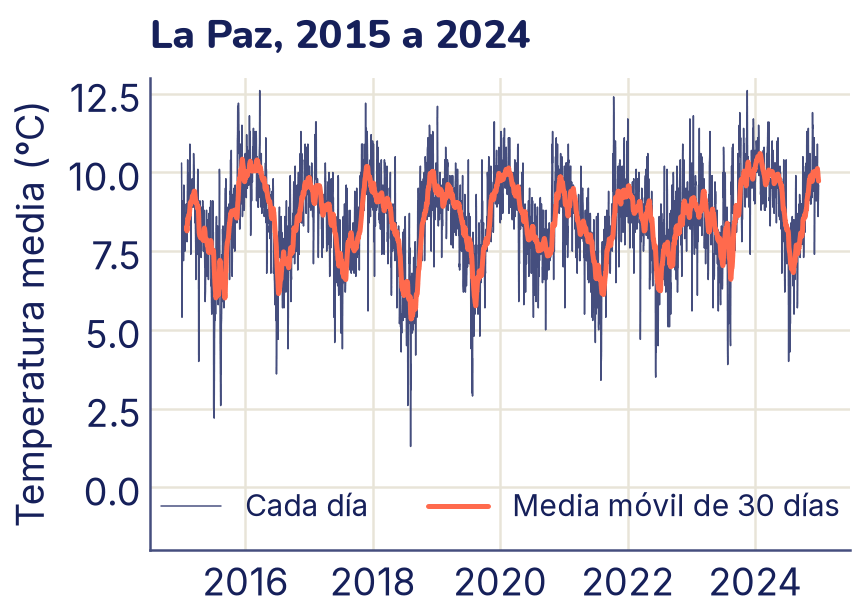

In [ ]:
import matplotlib.dates as mdates

print(f"Promedio de los diez años: {temp.mean():.1f} °C")
print(f"Día más frío: {temp.idxmin().date()}, {temp.min():.1f} °C")
print(f"Día más cálido: {temp.idxmax().date()}, {temp.max():.1f} °C")

# Media móvil: cada día, el promedio de ese día y los 29 anteriores
media_30 = temp.rolling(30).mean()

fig, ax = plt.subplots()
ax.plot(temp.index, temp, color="C2", linewidth=0.6, label="Cada día")
ax.plot(media_30.index, media_30, color="C1", linewidth=2,
        label="Media móvil de 30 días")
ax.set_ylabel("Temperatura media (°C)")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylim(-2, 13)
ax.set_title("La Paz, 2015 a 2024")
ax.legend(loc="lower center", ncol=2, fontsize=12)
plt.show()

En la figura se ven las tres piezas con las que se describe casi cualquier serie de tiempo:

- **Estacionalidad**: un patrón que se repite con un período fijo. Aquí, el ciclo de un año: el frío llega a mitad de año, en el invierno, y el calor hacia noviembre y diciembre.
- **Tendencia**: un cambio lento que no se repite, como una subida a lo largo de los años. En diez años de La Paz casi no se nota; los pasajeros de avión del tema 4, en cambio, tenían una tendencia clara.
- **Ruido**: lo que queda, los saltos de un día a otro que ni la estación ni la tendencia explican. Es lo que hace difícil predecir.

Para mirar la serie con otra frecuencia se **remuestrea**: `resample("MS")` junta los días de cada mes («MS», *month start*, rotula cada grupo con el primer día del mes) y `.mean()` los promedia; `resample("YS")` hace lo mismo por año. Es como un `groupby`, pero agrupando por intervalos de tiempo. Para ver la estacionalidad juntamos el mismo mes de todos los años con un `groupby` por el número de mes:

In [ ]:
# Remuestrear: pasar de días a meses (MS: comienzo de mes) o a años
por_mes = temp.resample("MS").mean()
print(por_mes.head(3).round(2))

anual = temp.resample("YS").mean()
print("Promedio de cada año:", anual.round(1).tolist())

# El mismo mes de todos los años, junto: la estacionalidad
clima = temp.groupby(temp.index.month).mean()
print("Promedio de cada mes, de enero a diciembre:")
print(clima.round(1).tolist())

fecha
2015-01-01    8.26
2015-02-01    9.14
2015-03-01    8.98
Freq: MS, Name: temp, dtype: float64
Promedio de cada año: [8.2, 8.8, 8.5, 8.1, 8.4, 8.7, 8.2, 8.2, 8.8, 9.1]
Promedio de cada mes, de enero a diciembre:
[9.4, 9.4, 9.1, 8.8, 8.2, 7.3, 7.0, 7.1, 7.9, 8.8, 9.6, 9.6]


Junio, julio y agosto son los meses más fríos (unos 7 °C de media) y noviembre y diciembre los más cálidos (9,6 °C). Entre años, el promedio se mueve entre 8,1 y 9,1 °C: 2024 fue el más cálido de los diez, pero con tan pocos años no alcanza para hablar de una tendencia.

## Rezagos y autocorrelación

Un **rezago** (en inglés, *lag*) es el valor de la serie unos días antes. El rezago 1 de hoy es la temperatura de ayer; el rezago 7, la de hace una semana. La **autocorrelación** con rezago *k* es la correlación (la del tema 4) entre la serie y ella misma corrida *k* días: mide cuánto se parece cada día al de *k* días antes. Pandas la calcula con `autocorr(lag=k)`.

Rezago   1: autocorrelación +0.84
Rezago   2: autocorrelación +0.71
Rezago   7: autocorrelación +0.52
Rezago  30: autocorrelación +0.42
Rezago 182: autocorrelación -0.32
Rezago 365: autocorrelación +0.40


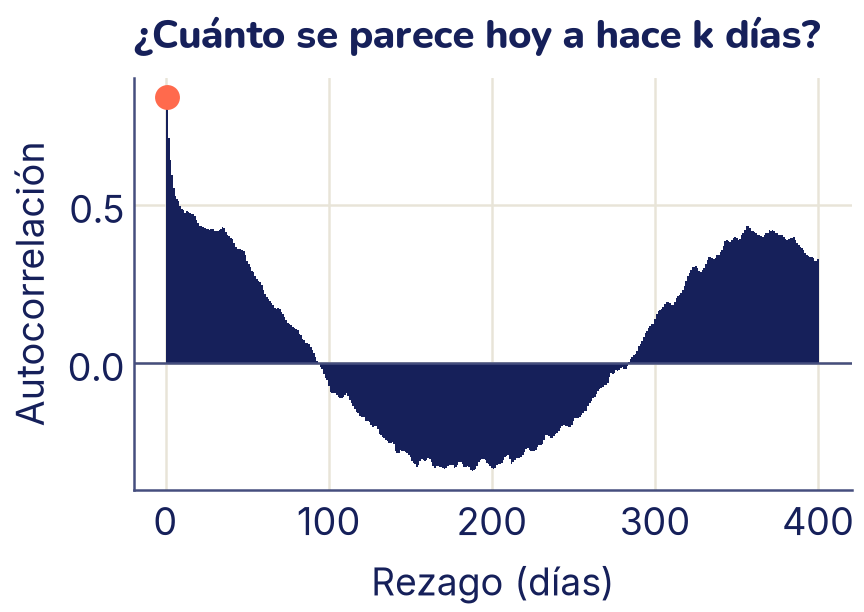

In [ ]:
for k in [1, 2, 7, 30, 182, 365]:
    print(f"Rezago {k:3d}: autocorrelación "
          f"{temp.autocorr(lag=k):+.2f}")

rezagos = np.arange(1, 401)
autocorr = [temp.autocorr(lag=k) for k in rezagos]

fig, ax = plt.subplots()
ax.bar(rezagos, autocorr, width=1.0, color="C0")
# Resaltamos el rezago de 1 día: ayer frente a hoy
ax.scatter([1], [autocorr[0]], color="C1", s=80, zorder=3)
ax.axhline(0, color="C2", linewidth=1)
ax.set_xlabel("Rezago (días)")
ax.set_ylabel("Autocorrelación")
ax.set_title("¿Cuánto se parece hoy a hace k días?")
plt.show()

La figura cuenta dos historias. A corto plazo, **ayer se parece mucho a hoy** (0,84) y el parecido se pierde rápido: con una semana de distancia ya es 0,52. Y a largo plazo aparece la estacionalidad: medio año después la correlación es negativa (invierno frente a verano) y al año vuelve a ser positiva, porque es la misma época.

En pandas, los rezagos se crean con **`shift`**. `shift(1)` corre los valores un lugar hacia abajo: cada fila recibe el valor de la fila anterior, es decir, el de ayer. `shift(-1)` los corre hacia arriba: cada fila recibe el de mañana. En la primera fila no hay ayer y en la última no hay mañana: ahí pandas pone `NaN`.

In [ ]:
tabla = pd.DataFrame({"temp": temp})
tabla["ayer"] = temp.shift(1)       # baja los valores un día
tabla["mañana"] = temp.shift(-1)    # los sube un día
print(tabla.head(3))
print(tabla.tail(2))

            temp  ayer  mañana
fecha                         
2015-01-01  10.3   NaN     9.3
2015-01-02   9.3  10.3     5.4
2015-01-03   5.4   9.3     5.4
            temp  ayer  mañana
fecha                         
2024-12-30   9.2   9.0     9.6
2024-12-31   9.6   9.2     NaN


## La ventana: de serie a tabla

Un modelo como `HistGradientBoostingRegressor` necesita una tabla: filas, columnas de entrada (*X*) y un objetivo (*y*). Con una serie, cada día se vuelve una fila. Sus columnas son lo que **ya se sabe ese día**: la temperatura de hoy, de ayer y de anteayer (rezagos), y resúmenes de la **ventana deslizante** de los últimos días. Esos **resúmenes estadísticos** son la media (dónde está la temperatura últimamente), la desviación estándar (cuánto viene variando), el mínimo y el máximo. El objetivo es el valor de dentro de *h* días, donde *h* es el **horizonte de predicción**:

$$\text{entradas} : {x}_{t} , {x}_{t - 1} , {x}_{t - 2} , {m}_{t} , \ldots$$

  
$$\text{objetivo} : {x}_{t + h}$$

La regla de oro: **todas las entradas usan solo días anteriores o iguales a *t***. Por eso la ventana es `rolling(dias)`, que termina en el día de la fila, y el objetivo usa `shift(-horizonte)`, que mira hacia adelante. Las primeras filas no tienen ventana completa y las últimas no tienen objetivo; las quitamos.

In [ ]:
def tabla_ventana(serie, dias=7, horizonte=1):
    """Una fila por día: lo que se sabe hoy y lo que pasará."""
    X = pd.DataFrame(index=serie.index)
    X["hoy"] = serie
    X["ayer"] = serie.shift(1)
    X["anteayer"] = serie.shift(2)
    # La ventana: hoy y los días anteriores, «dias» en total
    ventana = serie.rolling(dias)
    X["media"] = ventana.mean()
    X["desv"] = ventana.std()
    X["minimo"] = ventana.min()
    X["maximo"] = ventana.max()
    # El objetivo: el valor de dentro de «horizonte» días
    y = serie.shift(-horizonte)
    completas = X.notna().all(axis=1) & y.notna()
    return X[completas], y[completas]

X, y = tabla_ventana(temp)
print("Tabla:", X.shape)
print(X.loc["2024-06-20"].round(2).to_string())
print("objetivo:", y.loc["2024-06-20"])

Tabla: (3646, 7)
hoy          6.20
ayer         6.70
anteayer     8.10
media        7.87
desv         1.33
minimo       6.20
maximo      10.40
objetivo: 7.7


Perdimos 7 de los 3653 días: los 6 primeros, que no tienen 7 días de historia, y el último, que no tiene mañana. La fila del 20 de junio de 2024 es la misma que ves en la actividad cuando la abres: hoy hizo 6,2 °C, la semana promedió 7,87 °C y mañana hubo 7,7 °C. La figura muestra de dónde sale esa fila:

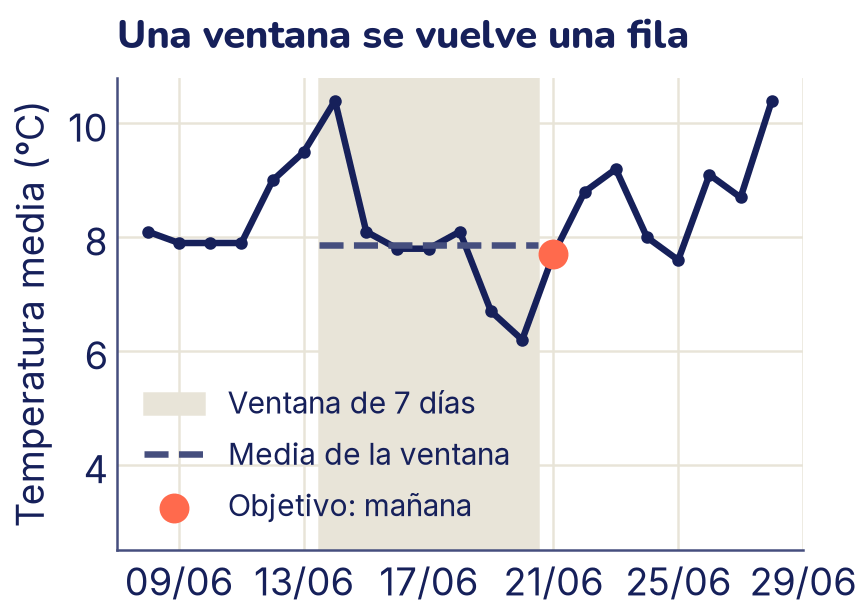

In [ ]:
hoy = pd.Timestamp("2024-06-20")
manana = hoy + pd.Timedelta(days=1)
inicio = hoy - pd.Timedelta(days=6)
medio_dia = pd.Timedelta(hours=12)
tramo = temp["2024-06-08":"2024-06-28"]

fig, ax = plt.subplots()
ax.axvspan(inicio - medio_dia, hoy + medio_dia, color="C3",
           label="Ventana de 7 días")
ax.plot(tramo.index, tramo, color="C0", marker="o", markersize=4)
ax.hlines(X.loc[hoy, "media"], inicio - medio_dia, hoy + medio_dia,
          color="C2", linestyles="--", label="Media de la ventana")
ax.scatter([manana], [temp[manana]], color="C1", s=120, zorder=3,
           label="Objetivo: mañana")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_ylabel("Temperatura media (°C)")
ax.set_ylim(2.5, 10.8)
ax.set_title("Una ventana se vuelve una fila")
ax.legend(loc="lower left", fontsize=12)
plt.show()

## Faltantes en una secuencia: forward-fill

Esta serie no tiene huecos, pero las reales casi siempre los tienen: un sensor que se apaga, un día sin registro. En el tema 10 imputabas con la media o la mediana. En una serie de tiempo eso tiene dos problemas: la media de toda la serie **usa días del futuro**, y un valor de enero rellenado con el promedio del año no se parece a enero.

Lo más común es el **forward-fill** (`ffill`, «rellenar hacia adelante»): cada hueco toma **el último valor conocido**. Es lo que sabrías en la vida real ese día: lo último que marcó el termómetro antes de fallar. Para probarlo, borramos a propósito algunos días (60 sueltos y una semana entera), rellenamos y comparamos con el valor real, que sí conocemos:

*La celda que sigue da un error a propósito: es parte de la explicación.*

In [ ]:
rng = np.random.default_rng(42)
con_huecos = temp.copy()
# Simulamos un termómetro que falla: 60 días sueltos y una semana entera
sueltos = rng.choice(np.arange(1, len(temp)), size=60, replace=False)
con_huecos.iloc[sueltos] = np.nan
con_huecos["2022-03-01":"2022-03-07"] = np.nan
faltan = con_huecos.isna()
print("Días sin dato:", faltan.sum())

# Forward-fill: cada hueco toma el último valor conocido
rellena = con_huecos.ffill()
print(pd.DataFrame({"con huecos": con_huecos, "ffill": rellena,
                    "real": temp})["2022-02-27":"2022-03-09"])
error = (rellena[faltan] - temp[faltan]).abs().mean()
print(f"Error medio en los días rellenados: {error:.2f} °C")

Días sin dato: 67
            con huecos  ffill  real
fecha                              
2022-02-27         9.1    9.1   9.1
2022-02-28         9.8    9.8   9.8
2022-03-01         NaN    9.8   8.7
2022-03-02         NaN    9.8   8.7
2022-03-03         NaN    9.8   9.0
2022-03-04         NaN    9.8   9.6
2022-03-05         NaN    9.8   9.4
2022-03-06         NaN    9.8   9.5
2022-03-07         NaN    9.8  10.0
2022-03-08         8.8    8.8   8.8
2022-03-09         8.4    8.4   8.4
Error medio en los días rellenados: 0.64 °C


En los días sueltos, el último valor conocido es el de ayer, que suele estar cerca (autocorrelación 0,84). En la semana entera, en cambio, el forward-fill repite el 9,8 °C del 28 de febrero siete veces: cuanto más largo el hueco, peor. Por eso conviene contar cuántos días seguidos faltan antes de confiar en el relleno, y en un hueco largo puede ser mejor descartar esas filas. Si la serie empieza con un hueco, `ffill` no tiene nada que copiar y deja `NaN`. En el ejercicio 5 comparas el forward-fill con la media y con la interpolación.

## La línea base: «mañana igual que hoy»

Antes de entrenar nada, hay que saber cuánto vale un pronóstico que no aprende nada. La **línea base** más simple es la **persistencia**: predecir que mañana hará lo mismo que hoy. Otra es predecir la media de la última semana. Si un modelo no les gana, no sirve, por complicado que sea.

Separamos un conjunto de prueba **por fecha**, no al azar: entrenamos con 2015 a 2022 y dejamos 2023 y 2024 como el «futuro». Medimos el error con el **MAE** del tema 6, en grados.

In [ ]:
from sklearn.metrics import mean_absolute_error

# Entrenamiento: 2015 a 2022. Prueba: 2023 y 2024, el «futuro»
ent = X.index < "2023-01-01"
X_ent, y_ent = X[ent], y[ent]
X_prueba, y_prueba = X[~ent], y[~ent]
print("Entrenamiento:", len(X_ent), "días   prueba:", len(X_prueba), "días")

# Dos líneas base que no aprenden nada
mae_hoy = mean_absolute_error(y_prueba, X_prueba["hoy"])
mae_media = mean_absolute_error(y_prueba, X_prueba["media"])
print(f"«Mañana igual que hoy»:           MAE = {mae_hoy:.3f} °C")
print(f"«Mañana igual que la semana»:     MAE = {mae_media:.3f} °C")

Entrenamiento: 2916 días   prueba: 730 días
«Mañana igual que hoy»:           MAE = 0.632 °C
«Mañana igual que la semana»:     MAE = 0.779 °C


«Mañana igual que hoy» se equivoca en promedio 0,63 °C, y le gana con claridad a la media de la semana. Es una vara alta: con una autocorrelación de 0,84, el mejor resumen del pasado suele ser el último día.

## Validar sin mirar el futuro

Para elegir un modelo necesitamos validación cruzada, como en el tema 7. Pero el `KFold` barajado pone días de 2022 en el entrenamiento y días de 2016 en la validación: el modelo aprende con el futuro para predecir el pasado. **`TimeSeriesSplit`** respeta el orden. Corta la serie en bloques consecutivos; en cada pliegue entrena con todo lo anterior a un bloque y valida con ese bloque. El entrenamiento crece de pliegue en pliegue, y la validación siempre es posterior.

Pliegue 1: entrena con  486 días, valida del 2016-05-07 al 2017-09-04
Pliegue 2: entrena con  972 días, valida del 2017-09-05 al 2019-01-03
Pliegue 3: entrena con 1458 días, valida del 2019-01-04 al 2020-05-03
Pliegue 4: entrena con 1944 días, valida del 2020-05-04 al 2021-09-01
Pliegue 5: entrena con 2430 días, valida del 2021-09-02 al 2022-12-31


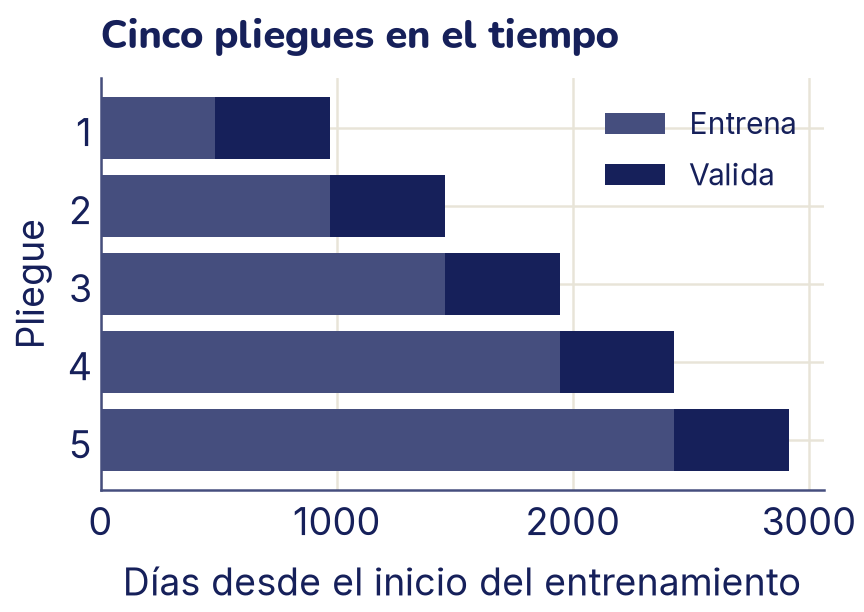

In [ ]:
from sklearn.model_selection import TimeSeriesSplit

tss = TimeSeriesSplit(n_splits=5)
fig, ax = plt.subplots()
for k, (i_ent, i_val) in enumerate(tss.split(X_ent), start=1):
    desde = X_ent.index[i_val[0]].date()
    hasta = X_ent.index[i_val[-1]].date()
    print(f"Pliegue {k}: entrena con {len(i_ent):4d} días, "
          f"valida del {desde} al {hasta}")
    ax.barh(k, len(i_ent), color="C2",
            label="Entrena" if k == 1 else None)
    ax.barh(k, len(i_val), left=len(i_ent), color="C0",
            label="Valida" if k == 1 else None)
ax.invert_yaxis()
ax.set_yticks(range(1, 6))
ax.set_xlabel("Días desde el inicio del entrenamiento")
ax.set_ylabel("Pliegue")
ax.set_title("Cinco pliegues en el tiempo")
ax.legend(loc="upper right", fontsize=12)
plt.show()

¿Tanto importa? Hagamos un experimento extremo. Un «modelo» de vecinos cercanos (tema 8) que solo conoce **la fecha**, el número de día, y nada de la temperatura. Para predecir la temperatura de mañana de un día cualquiera, busca los dos días más cercanos en el calendario que tenga en el entrenamiento y promedia sus objetivos.

In [ ]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor

# Un «modelo» que solo conoce la fecha: el número de día
dia_numero = np.arange(len(X_ent)).reshape(-1, 1)
vecinos = KNeighborsRegressor(n_neighbors=2)
barajada = KFold(n_splits=5, shuffle=True, random_state=0)

for nombre, cv in [("barajada", barajada), ("por tiempo", tss)]:
    # scikit-learn devuelve el MAE con signo menos (tema 7);
    # el - de adelante lo vuelve positivo
    errores = -cross_val_score(vecinos, dia_numero, y_ent, cv=cv,
                               scoring="neg_mean_absolute_error")
    rotulo = f"Solo la fecha, validación {nombre}:"
    print(f"{rotulo:38s} MAE = {errores.mean():.3f} °C")

base = mean_absolute_error(y_ent, X_ent["hoy"])
rotulo = "Línea base en el entrenamiento:"
print(f"{rotulo:38s} MAE = {base:.3f} °C")

Solo la fecha, validación barajada:    MAE = 0.541 °C
Solo la fecha, validación por tiempo:  MAE = 1.292 °C
Línea base en el entrenamiento:        MAE = 0.644 °C


Con validación barajada, ese modelo «le gana» a la línea base: 0,541 contra 0,644. Es mentira. Al barajar, el día anterior y el siguiente al que se valida suelen quedar en el entrenamiento: sus objetivos son la temperatura de hoy y la de pasado mañana, y su promedio se parece mucho a la de mañana. El modelo no aprendió nada sobre el clima: copió a los vecinos del futuro. Con `TimeSeriesSplit`, donde los vecinos de la validación no están, el error sube a 1,292: el doble que la línea base. Esa es la verdad.

### La otra fuga: una ventana que mira adelante

Aun dividiendo bien, la fuga se puede colar en las variables. Un error muy común es una media móvil **centrada** (`rolling(7, center=True)`), que promedia 3 días antes, el día y 3 días después. Dibujada sobre un gráfico queda muy bien, pero como entrada de un modelo incluye el objetivo y dos días más del futuro.

Usamos `HistGradientBoostingRegressor` del tema 11 con árboles poco profundos (`max_depth=3`) y una tasa de aprendizaje baja: con datos tan ruidosos, un modelo más flexible aprende el ruido y no le gana a la persistencia (pruébalo con los valores por defecto).

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

modelo = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05,
                                       max_iter=200, random_state=0)

# La fuga: una media «centrada» usa 3 días antes y 3 días después
X_fuga = X_ent.copy()
X_fuga["media"] = temp.rolling(7, center=True).mean()[X_ent.index]

for nombre, tabla_x in [("Ventana sin fuga", X_ent),
                        ("Ventana centrada", X_fuga)]:
    errores = -cross_val_score(modelo, tabla_x, y_ent, cv=tss,
                               scoring="neg_mean_absolute_error")
    print(f"{nombre}:  MAE = {errores.mean():.3f} °C")

# La línea base, en los mismos pliegues de validación
base_cv = [mean_absolute_error(y_ent.iloc[v], X_ent["hoy"].iloc[v])
           for _, v in tss.split(X_ent)]
print(f"Línea base:        MAE = {np.mean(base_cv):.3f} °C")

Ventana sin fuga:  MAE = 0.633 °C
Ventana centrada:  MAE = 0.446 °C
Línea base:        MAE = 0.649 °C


Con la ventana centrada, el error baja a 0,446 °C: más de un 30 % mejor que la línea base. Cuando un resultado es **demasiado bueno**, sospecha. Esa variable no existe el día que tienes que predecir: para calcularla hoy necesitarías saber la temperatura de los próximos tres días. Sin fuga, el modelo saca 0,633 frente a 0,649 de la línea base: una mejora chica, pero real.

## Predecir mañana

Ya elegimos la tabla y el modelo usando solo el entrenamiento. Ahora sí, entrenamos con 2015 a 2022 y medimos **una sola vez** con 2023 y 2024.

Modelo:               MAE = 0.616 °C
Mañana igual que hoy: MAE = 0.632 °C
El modelo se equivoca un 2.6 % menos


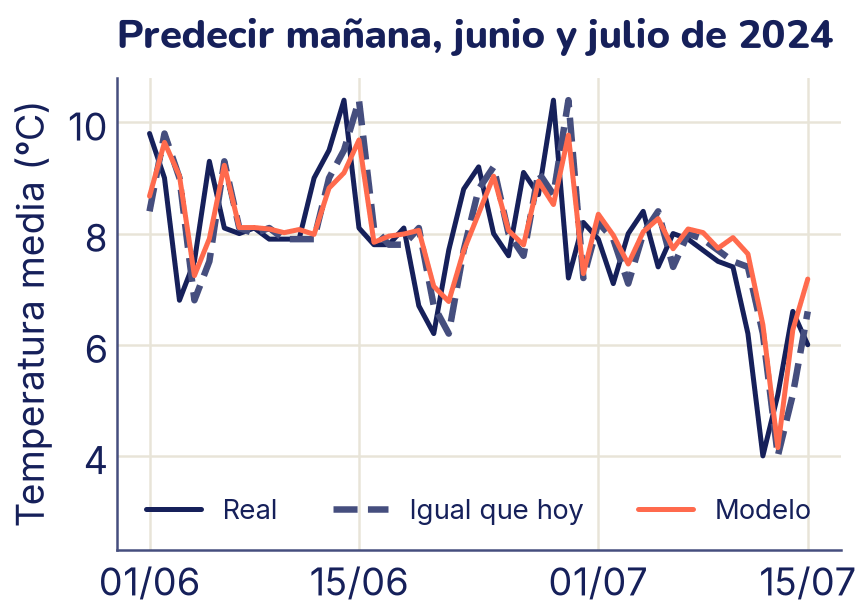

In [ ]:
modelo.fit(X_ent, y_ent)
pred = pd.Series(modelo.predict(X_prueba), index=X_prueba.index)

mae_modelo = mean_absolute_error(y_prueba, pred)
print(f"Modelo:               MAE = {mae_modelo:.3f} °C")
print(f"Mañana igual que hoy: MAE = {mae_hoy:.3f} °C")
mejora = 100 * (1 - mae_modelo / mae_hoy)
print(f"El modelo se equivoca un {mejora:.1f} % menos")

# Las fechas son las del objetivo: el día que se predice
dia_obj = X_prueba.index + pd.Timedelta(days=1)
real = pd.Series(y_prueba.values, index=dia_obj)
modelo_dia = pd.Series(pred.values, index=dia_obj)
base_dia = pd.Series(X_prueba["hoy"].values, index=dia_obj)
junio = slice("2024-06-01", "2024-07-15")

fig, ax = plt.subplots()
ax.plot(real[junio], color="C0", linewidth=2, label="Real")
ax.plot(base_dia[junio], color="C2", linestyle="--",
        label="Igual que hoy")
ax.plot(modelo_dia[junio], color="C1", linewidth=2, label="Modelo")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_ylabel("Temperatura media (°C)")
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 15]))
ax.set_ylim(2.3, 10.8)
ax.set_title("Predecir mañana, junio y julio de 2024")
ax.legend(loc="lower center", ncol=3, fontsize=11)
plt.show()

El modelo se equivoca 0,616 °C en promedio frente a 0,632 de la persistencia: un 2,6 % menos. En el gráfico se ve por qué la mejora es chica. La línea base es la curva real **corrida un día**: cada cambio brusco la toma por sorpresa. El modelo hace casi lo mismo, pero aprendió que después de un día muy cálido o muy frío la temperatura suele volver hacia la media de la semana, y recorta los picos. Los cambios bruscos, como el frío del 12 de julio, no los anticipa ninguno de los dos: con solo la temperatura de los días anteriores no hay forma de verlos venir. Los servicios meteorológicos usan mucha más información (presión, viento, humedad, lo que pasa en otros lugares) y modelos físicos de la atmósfera.

### El horizonte

¿Y si queremos predecir con más anticipación? Con `tabla_ventana(temp, horizonte=h)` cambiamos solo el objetivo:

In [ ]:
print("Horizonte   modelo   igual que hoy   (MAE en °C)")
for h in [1, 3, 7]:
    X_h, y_h = tabla_ventana(temp, horizonte=h)
    ent_h = X_h.index < "2023-01-01"
    modelo.fit(X_h[ent_h], y_h[ent_h])
    p = modelo.predict(X_h[~ent_h])
    m = mean_absolute_error(y_h[~ent_h], p)
    b = mean_absolute_error(y_h[~ent_h], X_h["hoy"][~ent_h])
    print(f"h = {h}       {m:.3f}    {b:.3f}")

Horizonte   modelo   igual que hoy   (MAE en °C)
h = 1       0.616    0.632
h = 3       0.847    0.936
h = 7       0.937    1.107


A más horizonte, más error para los dos, pero la persistencia empeora más rápido: a una semana, «igual que hoy» se equivoca 1,11 °C y el modelo 0,94. Cuanto más lejos el objetivo, menos sirve el último día y más valen la media de la ventana y lo que el modelo aprendió de las estaciones.

## Secuencias de largo variable

No toda secuencia es una serie con un dato por día. Las visitas a una página web, los intentos de un estudiante en un ejercicio o los viajes de un bus son **secuencias de largo variable**: una visita tiene 2 clics y otra 50. Un modelo de tabla necesita el mismo número de columnas en cada fila, así que **cada secuencia se resume en variables fijas**: cuántos eventos tuvo, cuánto duró, la pausa media, si pasó algo en particular. Es la misma idea de la ventana: resumir un tramo de tiempo con unos pocos números. Con `groupby` y `agg` sale en una línea por variable:

In [ ]:
# Datos sintéticos: los clics de tres visitas a una página web
clics = pd.DataFrame({
    "visita":   [1, 1, 1, 2, 2, 3, 3, 3, 3, 3],
    "segundo":  [0, 40, 95, 0, 300, 0, 12, 30, 41, 70],
    "pagina":   ["inicio", "tienda", "pago", "inicio", "blog",
                 "inicio", "tienda", "tienda", "tienda", "pago"],
})
resumen = clics.groupby("visita").agg(
    clics=("segundo", "size"),
    duracion=("segundo", "max"),
    pausa_media=("segundo", lambda s: s.diff().mean()),
    llego_a_pagar=("pagina", lambda p: (p == "pago").any()),
)
print(resumen)

        clics  duracion  pausa_media  llego_a_pagar
visita                                             
1           3        95         47.5           True
2           2       300        300.0          False
3           5        70         17.5           True


Tres secuencias de largos distintos (3, 2 y 5 clics) quedaron como tres filas con las mismas cuatro columnas, listas para un modelo. Los datos de este ejemplo son inventados.

## Lo que aprendiste y lo que sigue

- Una **serie de tiempo** es una tabla cuyo índice son fechas; el orden importa. Se describe con **tendencia**, **estacionalidad** y **ruido**, y se puede **remuestrear** a otra frecuencia con `resample`.
- La **autocorrelación** mide cuánto se parece la serie a sí misma *k* días antes. En La Paz, ayer explica mucho de hoy, y el ciclo anual vuelve a los 365 días.
- Una **ventana deslizante** convierte la serie en una tabla: rezagos con `shift`, resúmenes estadísticos con `rolling`, y el objetivo con `shift(-h)`. Todas las entradas deben usar solo el pasado.
- Para validar no se baraja: **`TimeSeriesSplit`** entrena con el pasado y valida con lo que sigue. Barajar o usar ventanas centradas produce **fuga temporal** y puntajes que mienten.
- El **forward-fill** rellena huecos con el último valor conocido, sin usar el futuro.
- Todo modelo se compara con una **línea base**. Ganarle a «mañana igual que hoy» es difícil a un día y más fácil a varios días.

Más adelante, los transformers (tema 23) leerán secuencias completas, como las frases de un texto, sin que tengas que resumirlas a mano en una ventana. Las reglas de este tema siguen valiendo para ellos: no mirar el futuro y compararse siempre con una línea base.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `temp`, `tabla_ventana`, `X` e `y`, `X_ent`, `y_ent`, `X_prueba`, `y_prueba`, `mae_hoy`, `con_huecos`, `faltan`, `tss`, `modelo`, `clics` y los `import`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

Los datos de temperatura son de [Weather data by Open-Meteo.com](https://open-meteo.com/) ([CC BY 4.0](https://creativecommons.org/licenses/by/4.0/deed.es)), calculados con el reanálisis ERA5-Land; las cifras de las respuestas son cálculos nuestros a partir de ellos.

## Ejercicios

### 1. Tendencia, estacionalidad y ruido

Para cada serie, di si esperas una tendencia, una estacionalidad (y con qué período) y mucho o poco ruido:

1. La temperatura media diaria de La Paz.
2. Los pasajeros mensuales de vuelos internacionales de 1949 a 1960 (tema 4).
3. La cantidad de personas que suben a un teleférico, hora por hora, durante un mes.
4. El precio de cierre diario de una acción en la bolsa.

<details>
<summary>Respuesta</summary>

1. Estacionalidad anual clara (frío a mitad de año) y mucho ruido de un día a otro; casi nada de tendencia en diez años.
2. Tendencia fuerte hacia arriba (se multiplican por más de cuatro) y estacionalidad anual, con un pico a mitad de año que crece con los años.
3. Dos estacionalidades a la vez: la del día (horas pico de mañana y de tarde, nada de madrugada) y la de la semana (los días hábiles no se parecen al domingo). La tendencia, en un mes, será pequeña.
4. Sobre todo ruido, con tendencias que cambian sin aviso y ninguna estacionalidad fuerte. Por eso, para el precio de mañana, «igual que hoy» es una línea base muy difícil de superar.

</details>

### 2. Rezagos a mano

Una serie de cinco días vale 10, 12, 11, 15 y 14. Sin computadora, escribe para cada día el valor de `shift(1)`, de `shift(-2)` y de `rolling(3).mean()`. ¿Por qué algunos quedan vacíos? Después compruébalo.

<details>
<summary>Respuesta</summary>

`shift(1)` le da a cada día el valor del día anterior; `shift(-2)`, el de dos días después; `rolling(3).mean()`, el promedio de ese día y los dos anteriores. Quedan vacíos (`NaN`) cuando no existe ese día: el primero no tiene ayer, los dos últimos no tienen «dentro de dos días» y los dos primeros no tienen tres días de historia.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
s = pd.Series([10, 12, 11, 15, 14],
              index=pd.date_range("2024-03-01", periods=5))
print(pd.DataFrame({"s": s, "shift(1)": s.shift(1),
                    "shift(-2)": s.shift(-2),
                    "media 3": s.rolling(3).mean().round(2)}))

### 3. Variables de calendario

La estacionalidad depende de la fecha, y la fecha es algo que sí se sabe de antemano. Agrega a la tabla el mes y la posición del día dentro del año. Para la posición, en lugar del número de día (de 1 a 366), usa su seno y su coseno: así el 31 de diciembre y el 1 de enero quedan cerca, como en un reloj, en vez de en los dos extremos. ¿Mejora la validación por tiempo del modelo?

La idea: pon los días del año sobre una circunferencia de radio 1, como las horas en un reloj. El día número *d* está en el ángulo 2π·*d*/365,25: el ángulo se mide en radianes, donde 2π es una vuelta entera (360°), así que en un año se da una vuelta. Las coordenadas del punto son (seno del ángulo, coseno del ángulo), las mismas que en el colegio se calculan en grados con un triángulo. El 1 de enero queda en (0,017; 1,000) y el 31 de diciembre (día 365) en (−0,004; 1,000): casi en el mismo lugar.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def con_calendario(X):
    """Agrega el mes y la posición del día dentro del año."""
    X = X.copy()
    dia = X.index.day_of_year
    X["mes"] = X.index.month
    # Seno y coseno: el 31 de diciembre queda pegado al 1 de enero
    X["dia_sin"] = np.sin(2 * np.pi * dia / 365.25)
    X["dia_cos"] = np.cos(2 * np.pi * dia / 365.25)
    return X

X_cal = con_calendario(X_ent)
print(X_cal[["mes", "dia_sin", "dia_cos"]].head(3).round(3))
for nombre, tabla_x in [("Sin calendario", X_ent),
                        ("Con calendario", X_cal)]:
    errores = -cross_val_score(modelo, tabla_x, y_ent, cv=tss,
                               scoring="neg_mean_absolute_error")
    print(f"{nombre}:  MAE = {errores.mean():.3f} °C")

<details>
<summary>Respuesta</summary>

Mejora un poco, de 0,633 a 0,620 °C. Con solo la temperatura de los últimos días, el modelo no sabe si va hacia el invierno o hacia el verano; la fecha se lo dice. Fíjate que el calendario **no es fuga**: la fecha de mañana se conoce hoy. Lo que no se puede usar es la temperatura de mañana.

</details>

### 4. Encuentra la fuga

Alguien te pasa este cuaderno, orgulloso de su MAE. Encuentra los problemas antes de abrir la respuesta. Una pista: hay más de uno.

In [ ]:
# El cuaderno de otra persona: ¿dónde está la fuga?
# Para cada día, el promedio de su semana de calendario
semana = temp.groupby(temp.index.to_period("W")).transform("mean")
X_mal = X.copy()
X_mal["media_semana"] = semana[X.index]
cv = KFold(n_splits=5, shuffle=True, random_state=0)
errores = -cross_val_score(modelo, X_mal, y, cv=cv,
                           scoring="neg_mean_absolute_error")
print(f"MAE del cuaderno con fugas: {errores.mean():.3f} °C")

MAE del cuaderno con fugas: 0.538 °C


<details>
<summary>Respuesta</summary>

Hay tres fugas:

1. **`media_semana`** promedia la semana de calendario completa (de lunes a domingo) a la que pertenece cada día. Para un martes incluye el miércoles (el objetivo) y los días siguientes: datos del futuro.
2. **`KFold(shuffle=True)`** baraja los días: el modelo entrena con días posteriores a los que valida.
3. Usa **`X` e `y` completos**, incluidos 2023 y 2024, que habíamos guardado como prueba. Si eliges el modelo mirando la prueba, ya no es una prueba.

Corregido: sin `media_semana`, solo con el entrenamiento y con `TimeSeriesSplit`:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
errores = -cross_val_score(modelo, X_ent, y_ent, cv=tss,
                           scoring="neg_mean_absolute_error")
print(f"MAE corregido:              {errores.mean():.3f} °C")

<details>
<summary>Respuesta (sigue)</summary>

El error «sube» de 0,538 a 0,633 °C. No es que el modelo empeorara: 0,633 es lo que de verdad se puede esperar, apenas mejor que la línea base.

</details>

### 5. Forward-fill frente a la media

Con `con_huecos` de la teoría, rellena los faltantes de tres formas: con forward-fill, con la media de toda la serie y con `interpolate()`, que traza una recta entre el último valor conocido y el siguiente. Compara el error en los días rellenados. ¿Cuál usarías para predecir en tiempo real, día a día?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
rellenos = {
    "ffill": con_huecos.ffill(),
    "media de toda la serie": con_huecos.fillna(con_huecos.mean()),
    "interpolación": con_huecos.interpolate(),
}
for nombre, serie in rellenos.items():
    error = (serie[faltan] - temp[faltan]).abs().mean()
    print(f"{nombre:24s} error medio = {error:.2f} °C")

<details>
<summary>Respuesta</summary>

- La **media de toda la serie** es la peor (1,08 °C): un hueco en julio recibe el promedio del año, que es de otra estación. Además usa el futuro: el promedio incluye días posteriores al hueco.
- La **interpolación** es la mejor (0,50 °C), porque usa el valor de antes y el de después. Justamente por eso no sirve para predecir en tiempo real: el día del hueco todavía no conoces el valor siguiente. Sirve para limpiar datos históricos que no vas a usar para evaluar un pronóstico.
- El **forward-fill** (0,64 °C) solo usa el pasado: es lo que tendrías de verdad ese día. Es la opción segura para un modelo que predice el futuro.

</details>

### 6. Otra línea base: la climatología

Además de «mañana igual que hoy», hay otra línea base clásica: la **climatología**, predecir para cada fecha el promedio de ese mismo día del año en los años de entrenamiento. Calcúlala para 2023 y 2024 con horizontes de 1 y de 7 días y compárala con la persistencia. ¿Cuál conviene en cada caso?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
# Climatología: el promedio de ese mismo día del año, 2015 a 2022
pasado = temp[:"2022-12-31"]
clima_dia = pasado.groupby(pasado.index.day_of_year).mean()

print("Horizonte   climatología   igual que hoy   (MAE en °C)")
for h in [1, 7]:
    X_h, y_h = tabla_ventana(temp, horizonte=h)
    prueba_h = X_h.index >= "2023-01-01"
    # El día que se predice, como número de día del año
    dias_obj = (X_h.index[prueba_h] + pd.Timedelta(days=h)).day_of_year
    pred_clima = clima_dia.loc[dias_obj].to_numpy()
    c = mean_absolute_error(y_h[prueba_h], pred_clima)
    b = mean_absolute_error(y_h[prueba_h], X_h["hoy"][prueba_h])
    print(f"h = {h}       {c:.3f}          {b:.3f}")

<details>
<summary>Respuesta</summary>

A un día, la persistencia gana con claridad (0,632 frente a 1,034 °C): ayer dice mucho más que el calendario. A siete días se invierte: «igual que hoy» se equivoca 1,107 °C y la climatología, que no depende del horizonte, 1,030 °C. Por eso un modelo con buenas variables mezcla las dos ideas: la ventana reciente y la época del año. En la teoría, a 7 días el modelo llegó a 0,937 °C, mejor que las dos líneas base.

</details>

### 7. Remuestrear

¿Cuál fue la semana más fría de los diez años? ¿Cuántos días con una media de menos de 5 °C hubo cada año? Usa `resample`.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
semanal = temp.resample("W").mean()
print("Semana más fría, la que termina el",
      semanal.idxmin().date(), f"con {semanal.min():.1f} °C")

# Días con una media de menos de 5 °C, año por año
frios = (temp < 5).resample("YS").sum()
print(frios.set_axis(frios.index.year).to_string())

<details>
<summary>Respuesta</summary>

`resample("W")` agrupa por semanas que terminan en domingo, y rotula cada grupo con ese domingo. Para contar días, `temp < 5` da una serie de `True` y `False`, y al sumar, cada `True` cuenta 1. Los años con más días fríos fueron 2015 y 2018 (15 cada uno); en 2020 no hubo ninguno.

</details>

### 8. Más variables para secuencias de largo variable

A partir de `clics`, agrega dos variables por visita: cuántas páginas distintas visitó y la pausa más larga entre dos clics. ¿Qué visita parece la de alguien que se distrajo?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
resumen_2 = clics.groupby("visita").agg(
    paginas_distintas=("pagina", "nunique"),
    pausa_maxima=("segundo", lambda s: s.diff().max()),
)
print(resumen_2)

<details>
<summary>Respuesta</summary>

La visita 2: solo dos clics y una pausa de 300 segundos entre ellos, sin llegar a pagar. La visita 3 tiene muchos clics seguidos en la tienda y termina pagando. Cada visita, de cualquier largo, queda como una fila con las mismas columnas.

</details>

## Mini-proyecto: la temperatura de mañana en Cochabamba

Repite todo el tema con otra ciudad, ahora con tres variables por día, y supera a la línea base.

1. Escribe una función `descargar(latitud, longitud, variables)` que pida a Open-Meteo la temperatura media, máxima y mínima diarias de Cochabamba (latitud −17,39, longitud −66,16) de 2015 a 2024. Revisa los faltantes y, si los hay, rellénalos con forward-fill. Grafica la media con su media móvil de 30 días (la referencia no incluye el gráfico).
2. Arma la tabla con `tabla_ventana` sobre la media y agrega la máxima y la mínima de hoy y las variables de calendario del ejercicio 3.
3. Deja 2023 y 2024 como prueba. Con `TimeSeriesSplit`, compara la línea base, el modelo con solo la ventana y el modelo con todo.
4. Mide **una sola vez** con la prueba y reporta cuánto mejora el modelo a la línea base.
5. Escribe tres frases: qué variables ayudaron, por qué no barajaste y qué información le falta al modelo para predecir mejor.

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
def descargar(latitud, longitud, variables):
    """Temperatura diaria de 2015 a 2024 desde Open-Meteo."""
    parametros = {
        "latitude": latitud, "longitude": longitud,
        "start_date": "2015-01-01", "end_date": "2024-12-31",
        "daily": ",".join(variables), "models": "era5_land",
        "timezone": "America/La_Paz", "format": "csv",
    }
    url = API + "?" + urlencode(parametros)
    tabla = pd.read_csv(url, skiprows=3, index_col=0,
                        parse_dates=True)
    tabla.columns = variables
    tabla.index.name = "fecha"
    return tabla

# Cochabamba
cbba = descargar(-17.39, -66.16, ["temperature_2m_mean",
                                  "temperature_2m_max",
                                  "temperature_2m_min"])
cbba.columns = ["media", "maxima", "minima"]
print(cbba.describe().round(1))
print("Faltantes:", cbba.isna().sum().sum())
cbba = cbba.ffill()                 # por si hubiera huecos

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
# Paso 2: la tabla de la ventana y dos variables más de hoy
Xc, yc = tabla_ventana(cbba["media"])
Xc["maxima_hoy"] = cbba["maxima"][Xc.index]
Xc["minima_hoy"] = cbba["minima"][Xc.index]
Xc = con_calendario(Xc)

ent_c = Xc.index < "2023-01-01"
Xc_ent, yc_ent = Xc[ent_c], yc[ent_c]
Xc_prueba, yc_prueba = Xc[~ent_c], yc[~ent_c]

# Paso 3: validación por bloques de tiempo
for nombre, columnas in [("Solo la ventana", X.columns),
                         ("Todo", Xc.columns)]:
    errores = -cross_val_score(modelo, Xc_ent[columnas], yc_ent,
                               cv=tss,
                               scoring="neg_mean_absolute_error")
    print(f"{nombre:16s} MAE de validación = {errores.mean():.3f}")
base_c = [mean_absolute_error(yc_ent.iloc[v], Xc_ent["hoy"].iloc[v])
          for _, v in tss.split(Xc_ent)]
print(f"{'Línea base':16s} MAE de validación = {np.mean(base_c):.3f}")

# Paso 4: una sola vez, la prueba con 2023 y 2024
modelo.fit(Xc_ent, yc_ent)
mae_c = mean_absolute_error(yc_prueba, modelo.predict(Xc_prueba))
mae_base_c = mean_absolute_error(yc_prueba, Xc_prueba["hoy"])
print(f"Prueba:  modelo {mae_c:.3f} °C   "
      f"igual que hoy {mae_base_c:.3f} °C")

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

- Cochabamba, en estos datos, promedia 15,9 °C, con máximas de unos 22 °C y mínimas de unos 11 °C. Recuerda que es el promedio de una celda de unos 11 km que incluye cerros alrededor del valle, así que puede ser más fresco que la ciudad. Tampoco hay faltantes, así que el forward-fill no cambia nada; la línea queda en el código por si otra ciudad los tiene.
- En la validación por tiempo, la línea base se equivoca 0,888 °C; el modelo con solo la ventana, 0,853, y con la máxima, la mínima y el calendario, 0,808: un 9 % menos que la línea base.
- En la prueba (2023 y 2024), el modelo se equivoca 0,782 °C y la línea base 0,803: la mejora se achica a un 2,6 %. Es normal que la prueba dé distinto que la validación: son otros años, con otro clima.
- Al modelo le falta lo que mueve el clima de un día a otro y no está en la temperatura: nubes, humedad, viento, lo que viene de otras regiones.

</details>

## Errores comunes

- **Barajar una serie de tiempo.** `train_test_split` baraja por defecto, y `KFold`, con `shuffle=True`. Para una serie, divide por fecha y valida con `TimeSeriesSplit`.
- **Ventanas que miran adelante.** `rolling(..., center=True)`, los promedios de la semana o del mes completos y cualquier `shift` negativo en una entrada meten el futuro en la fila. Pregúntate por cada columna: ¿la sabría el día de la predicción?
- **Olvidar la línea base.** Un MAE de 0,6 °C suena muy bien hasta que ves que «mañana igual que hoy» saca casi lo mismo. Compara siempre, y en los mismos días.
- **Confundir el sentido de `shift`.** `shift(1)` trae el pasado (ayer); `shift(-1)` trae el futuro (mañana). El objetivo se construye con `shift(-h)`; las entradas, nunca.
- **Imputar con la media de toda la serie o interpolar antes de evaluar.** Las dos usan datos posteriores al hueco. Para un modelo que predice, usa forward-fill.
- **Usar el índice como texto.** Si las fechas no son de tipo fecha, `resample`, `rolling` con fechas y los cortes como `temp["2024-06"]` no funcionan. Convierte con `parse_dates=True` o `pd.to_datetime`.
- **Medir con la prueba varias veces.** Elige con la validación por tiempo y usa 2023 y 2024 una sola vez, al final.
- **Descargar un rango que todavía no terminó.** Si pides datos hasta hoy, cada ejecución da otros números. Para estudiar y comparar, usa un rango fijo y pasado.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Cargar y graficar una serie con índice de fechas en pandas, y remuestrearla (ejercicio 7 y paso 1 del mini-proyecto).
- Crear variables de ventana deslizante: rezagos, media y desviación móviles (ejercicios 2 y 3 y paso 2 del mini-proyecto).
- Dividir respetando el tiempo con `TimeSeriesSplit` y explicar por qué no se baraja (ejercicio 4 y pasos 3 y 5 del mini-proyecto).
- Imputar faltantes en secuencias con forward-fill y explicar por qué la media y la interpolación usan el futuro (ejercicio 5).
- Comparar un modelo con una línea base ingenua (ejercicio 6 y paso 4 del mini-proyecto).
- Resumir secuencias de largo variable en variables fijas (ejercicio 8).